# Practice 3: Data Transformation & EDA

## Dataset: Students Performance

This dataset contains information about students and their exam performance.
It includes categorical variables such as gender, race/ethnicity, parental level of education, lunch, and test preparation course.

It also contains numerical variables: math score, reading score, and writing score.

The dataset will be used to practice data grouping, joins, reshaping, visualization, and exploratory data analysis (EDA).

In [1]:
 import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading the Dataset

The dataset is loaded into a Pandas DataFrame. The first five rows are displayed to understand its structure and variables.

In [3]:
import os

os.listdir('/content')

['.config', 'StudentsPerformance.csv.xls', 'sample_data']

In [4]:
df = pd.read_csv('/content/StudentsPerformance.csv.xls')

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## Dataset Overview

Before starting the analysis, we examine the structure of the dataset, including its size, data types, and missing values.

In [5]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1000, 8)

Data types:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


## Task 1 — GroupBy

First, the data is grouped by gender to compare students' average math, reading, and writing scores.

Then, the data is grouped by gender and test preparation course. Multiple aggregation functions are used to create a more detailed summary table.

In [6]:
grouped_gender = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].agg(['mean', 'min', 'max'])

grouped_gender

math score          reading score          writing score         
             mean min  max          mean min  max          mean min  max
gender                                                                  
female  63.633205   0  100     72.608108  17  100     72.467181  10  100
male    68.728216  27  100     65.473029  23  100     63.311203  15  100

### Grouping by Two Categorical Variables

The dataset is grouped by gender and test preparation course. The mean and count are calculated for math, reading, and writing scores to compare the groups.

In [7]:
grouped_two = df.groupby(
    ['gender', 'test preparation course']
).agg({
    'math score': ['mean', 'count'],
    'reading score': ['mean', 'count'],
    'writing score': ['mean', 'count']
})

grouped_two

math score       reading score        \
                                     mean count          mean count   
gender test preparation course                                        
female completed                67.195652   184     77.375000   184   
       none                     61.670659   334     69.982036   334   
male   completed                72.339080   174     70.212644   174   
       none                     66.688312   308     62.795455   308   

                               writing score        
                                        mean count  
gender test preparation course                      
female completed                   78.793478   184  
       none                        68.982036   334  
male   completed                   69.793103   174  
       none                        59.649351   308

## Task 2 — Joins

A second DataFrame is created with `race/ethnicity` as a common key.
It contains a short description for each student group. This DataFrame will be combined with the original dataset using inner and left joins.

In [8]:
group_info = pd.DataFrame({
    'race/ethnicity': ['group A', 'group B', 'group C', 'group D'],
    'group description': [
        'Student Group A',
        'Student Group B',
        'Student Group C',
        'Student Group D'
    ]
})

group_info

,race/ethnicity,group description
0,group A,Student Group A
1,group B,Student Group B
2,group C,Student Group C
3,group D,Student Group D


### Inner Join

An inner join keeps only the rows where the common key exists in both DataFrames. In this case, students from Group E will not be included because Group E is not present in the second DataFrame.

In [9]:
inner_join = pd.merge(
    df,
    group_info,
    on='race/ethnicity',
    how='inner'
)

print("Original dataset shape:", df.shape)
print("Inner join shape:", inner_join.shape)

inner_join.head()

Original dataset shape: (1000, 8)
Inner join shape: (860, 9)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,group description
0,female,group B,bachelor's degree,standard,none,72,72,74,Student Group B
1,female,group C,some college,standard,completed,69,90,88,Student Group C
2,female,group B,master's degree,standard,none,90,95,93,Student Group B
3,male,group A,associate's degree,free/reduced,none,47,57,44,Student Group A
4,male,group C,some college,standard,none,76,78,75,Student Group C


### Left Join

A left join keeps all rows from the original dataset. If a matching key is not found in the second DataFrame, the new column contains a missing value.

The results of the inner and left joins are compared below.

In [10]:
left_join = pd.merge(
    df,
    group_info,
    on='race/ethnicity',
    how='left'
)

print("Original dataset shape:", df.shape)
print("Inner join shape:", inner_join.shape)
print("Left join shape:", left_join.shape)

print("\nMissing descriptions in left join:")
print(left_join['group description'].isnull().sum())

left_join.head()

Original dataset shape: (1000, 8)
Inner join shape: (860, 9)
Left join shape: (1000, 9)

Missing descriptions in left join:
140


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,group description
0,female,group B,bachelor's degree,standard,none,72,72,74,Student Group B
1,female,group C,some college,standard,completed,69,90,88,Student Group C
2,female,group B,master's degree,standard,none,90,95,93,Student Group B
3,male,group A,associate's degree,free/reduced,none,47,57,44,Student Group A
4,male,group C,some college,standard,none,76,78,75,Student Group C


## Task 3 — Reshaping

### Pivot Table

A pivot table is created to compare the average math, reading, and writing scores by gender and test preparation course.

In [11]:
pivot_table = pd.pivot_table(
    df,
    values=['math score', 'reading score', 'writing score'],
    index='gender',
    columns='test preparation course',
    aggfunc='mean'
)

pivot_table

math score            reading score             \
test preparation course  completed       none     completed       none   
gender                                                                   
female                   67.195652  61.670659     77.375000  69.982036   
male                     72.339080  66.688312     70.212644  62.795455   

                        writing score             
test preparation course     completed       none  
gender                                            
female                      78.793478  68.982036  
male                        69.793103  59.649351

### Wide to Long Format using Melt

The math, reading, and writing score columns are transformed from wide format to long format using `melt()`. This creates one column for the subject and another column for the corresponding score.

In [12]:
melted_df = df.melt(
    id_vars=['gender', 'race/ethnicity'],
    value_vars=['math score', 'reading score', 'writing score'],
    var_name='subject',
    value_name='score'
)

melted_df.head(10)

,gender,race/ethnicity,subject,score
0,female,group B,math score,72
1,female,group C,math score,69
2,female,group B,math score,90
3,male,group A,math score,47
4,male,group C,math score,76
5,female,group B,math score,71
6,female,group B,math score,88
7,male,group B,math score,40
8,male,group D,math score,64
9,female,group B,math score,38


## Task 4 — Visualization

### Plot 1: Distribution of Math Scores

This histogram shows the distribution of students' math scores. It helps to see the most common score ranges and the overall spread of the results.

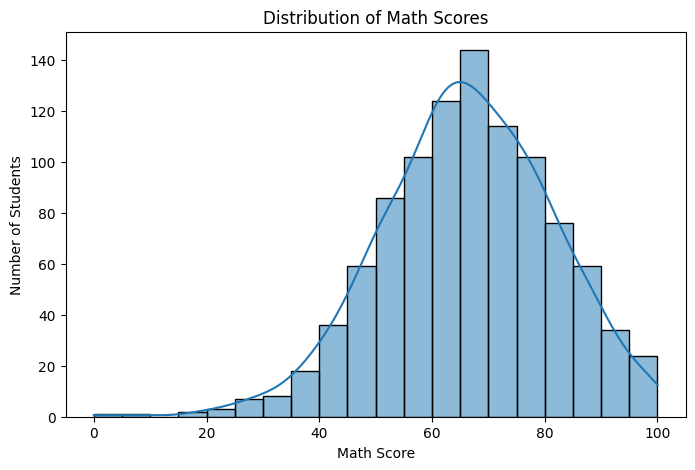

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='math score', bins=20, kde=True)

plt.title('Distribution of Math Scores')
plt.xlabel('Math Score')
plt.ylabel('Number of Students')

plt.show()

### Plot 2: Number of Students by Race/Ethnicity

This bar chart compares the number of students in each race/ethnicity group. It shows how students are distributed across the five categories.

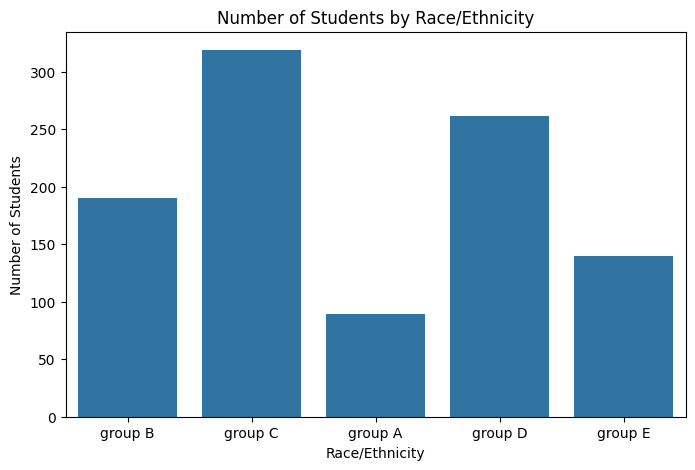

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='race/ethnicity')

plt.title('Number of Students by Race/Ethnicity')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Number of Students')

plt.show()

### Plot 3: Reading Score vs Writing Score

This scatter plot shows the relationship between reading and writing scores. It helps to identify whether students with higher reading scores also tend to have higher writing scores.

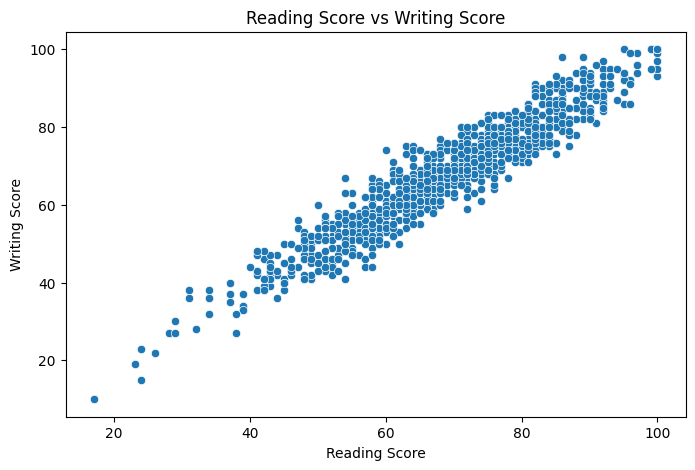

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='reading score',
    y='writing score'
)

plt.title('Reading Score vs Writing Score')
plt.xlabel('Reading Score')
plt.ylabel('Writing Score')

plt.show()

### Plot 4: Math Scores by Test Preparation Course

This box plot compares math scores between students who completed the test preparation course and students who did not. It helps to compare the score distributions and median values between the two groups.

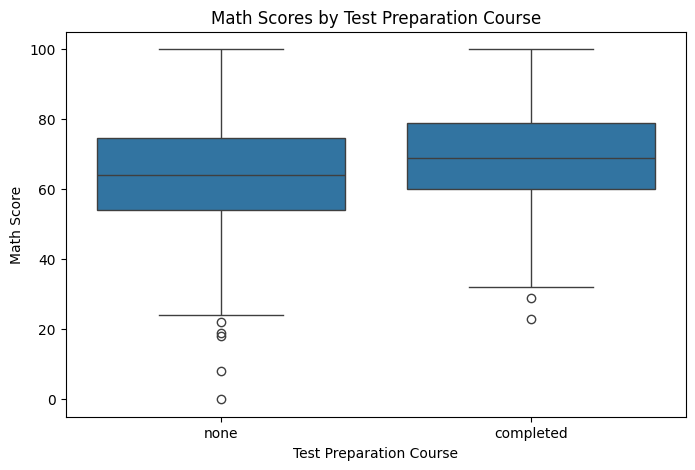

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='test preparation course',
    y='math score'
)

plt.title('Math Scores by Test Preparation Course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Math Score')

plt.show()

## Task 5 — Exploratory Data Analysis (EDA)

Grouped statistics are used to compare student performance across different categories. The analysis focuses on gender, test preparation course, and exam scores.

In [17]:
eda_stats = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean().round(2)

eda_stats

,math score,reading score,writing score
test preparation course,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


### Final Findings

1. **Gender differences:** Male students have a higher average math score (68.73) than female students (63.63). However, female students have higher average reading and writing scores.

2. **Test preparation:** Students who completed the test preparation course performed better in all three subjects. Their average scores were 69.70 in math, 73.89 in reading, and 74.42 in writing.

3. **Reading and writing relationship:** The scatter plot shows a strong positive relationship between reading and writing scores. Students with higher reading scores generally also have higher writing scores.

4. **Math score distribution:** Most math scores are concentrated around the middle and higher score ranges, especially around 60–80 points.

5. **Race/ethnicity distribution:** Group C has the largest number of students, while Group A has the smallest number of students in the dataset.

# Practice 3: Data Transformation & EDA

**Dataset:** Students Performance in Exams  
**Source:** https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

The dataset contains 1000 rows and 8 columns. It includes categorical variables such as gender, race/ethnicity, parental level of education, lunch, and test preparation course, as well as numerical variables such as math, reading, and writing scores.